### **Dataset and Exploratory Data Analysis (EDA)**

---
- Load and inspect data
- Check missing values
- Visualize dataset
- Investigate relationships
- Optimize dataset


```
inputs: Crop_recommendation.csv
outputs: clean_crop.parquet
```










 **Load and inspect**

In [ ]:
#Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')

In [ ]:
df = pd.read_csv('Crop_recommendation.csv')
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [ ]:
print("Shape:", df.shape) #dataset have 2200 rows, 8 columns (7 of which are our FEATURES and 1 is our target)
print(df.info()) #the dataset have no null values

Shape: (2200, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB
None


In [ ]:
print(df.describe()) #get numeric statistics of the FEATURES

                 N            P            K  temperature     humidity  \
count  2200.000000  2200.000000  2200.000000  2200.000000  2200.000000   
mean     50.551818    53.362727    48.149091    25.616244    71.481779   
std      36.917334    32.985883    50.647931     5.063749    22.263812   
min       0.000000     5.000000     5.000000     8.825675    14.258040   
25%      21.000000    28.000000    20.000000    22.769375    60.261953   
50%      37.000000    51.000000    32.000000    25.598693    80.473146   
75%      84.250000    68.000000    49.000000    28.561654    89.948771   
max     140.000000   145.000000   205.000000    43.675493    99.981876   

                ph     rainfall  
count  2200.000000  2200.000000  
mean      6.469480   103.463655  
std       0.773938    54.958389  
min       3.504752    20.211267  
25%       5.971693    64.551686  
50%       6.425045    94.867624  
75%       6.923643   124.267508  
max       9.935091   298.560117  


In [ ]:
print("Crops:",df['label'].unique()) #get crop types
print("\nNumber of crop types: ", df['label'].nunique()) #get the number of crop types
print("\nCount of each sample in the crops:\n",df['label'].value_counts())

Crops: ['rice' 'maize' 'chickpea' 'kidneybeans' 'pigeonpeas' 'mothbeans'
 'mungbean' 'blackgram' 'lentil' 'pomegranate' 'banana' 'mango' 'grapes'
 'watermelon' 'muskmelon' 'apple' 'orange' 'papaya' 'coconut' 'cotton'
 'jute' 'coffee']

Number of crop types:  22

Count of each sample in the crops:
 label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


**Check for missing values and duplicates**

In [ ]:
print("Missing values per coulumn:\n",df.isnull().sum())
print("\nDuplicate rows:",df.duplicated().sum())

Missing values per coulumn:
 N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0


The dataset was examined for missing values and duplicates and nothing was found therefor no removal was required.

**Visualization Figures**

In [ ]:
#specify what are the FEATURES we will use in our database to predict the crop type or label
FEATURES = ["N","P","K","temperature","humidity","ph","rainfall"]
TARGET = "label"

# **Figure 1 Crop Type Distribution**
Fig1 shows the crop type distribution 'label' which is our target for classifcation. The figure shows that there are 22 crop classes with 100 samples each. This means that the dataset have balanced number of samples across all classes.

Accuracy will be a good evaluation metric here since the classes have equal number of samples. Recall, precision, f1, and confusion matrix are also needed to understand how many crops the model predicted correctly

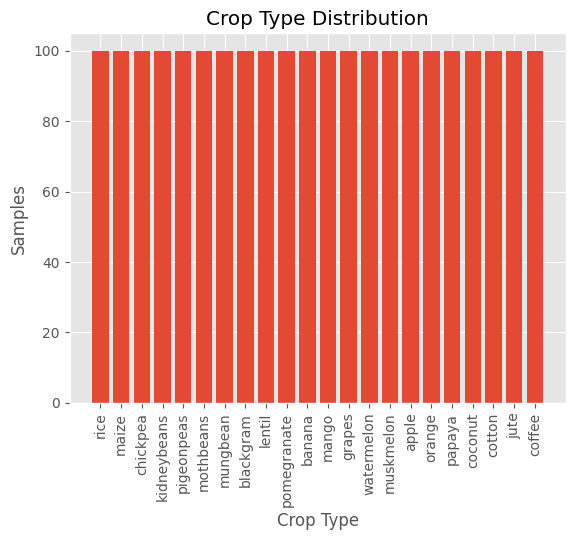

In [ ]:
counts = df[TARGET].value_counts()
plt.bar(counts.index, counts.values)
plt.title('Crop Type Distribution')
plt.xlabel('Crop Type')
plt.ylabel('Samples')
plt.xticks(rotation=90)
plt.savefig('fig1_crop_type_distribution.png')
plt.show()
#each crop type have 100 samples to use in our model


## **Figure 2 feature distribution**
FEATURES in the dataset have different distributions where some of the distributions are uneven having multiple peaks.

This model help you understand the data or FEATURES, but doesnt necessarily indicate which feature is important for the classification but it helps us understand the spread and what needs to be scaled for a model like logistic regression

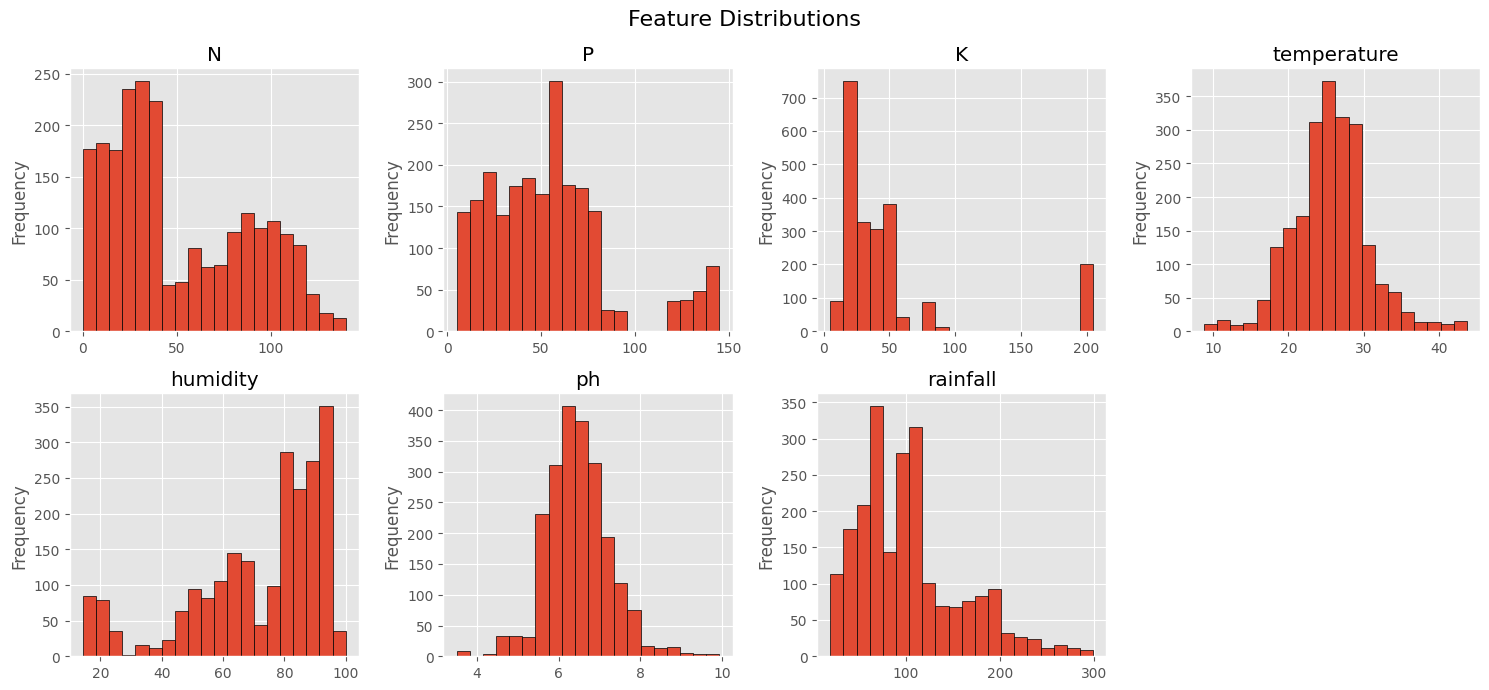

In [ ]:
#show the distribution of each feature and note their difference
fig, axes = plt.subplots(2, 4, figsize = (15, 7))
fig.suptitle("Feature Distributions", fontsize = 16)
for ax, c in zip(axes.ravel(), FEATURES):
  ax.hist(df[c], bins = 20, edgecolor = "black")
  ax.set_title(c)
  ax.set_ylabel("Frequency")

for ax in axes.ravel()[len(FEATURES):]:
    ax.axis("off")

plt.tight_layout()
plt.savefig('fig2_feature_distributions.png')
plt.show()


## **Figure 3 Feature Boxplot**
The boxplots help visualize the outliers found in the dataset. Phosphorus, potassium, humidity, ph, and rainfall contain outliers, but not in hydrogen.

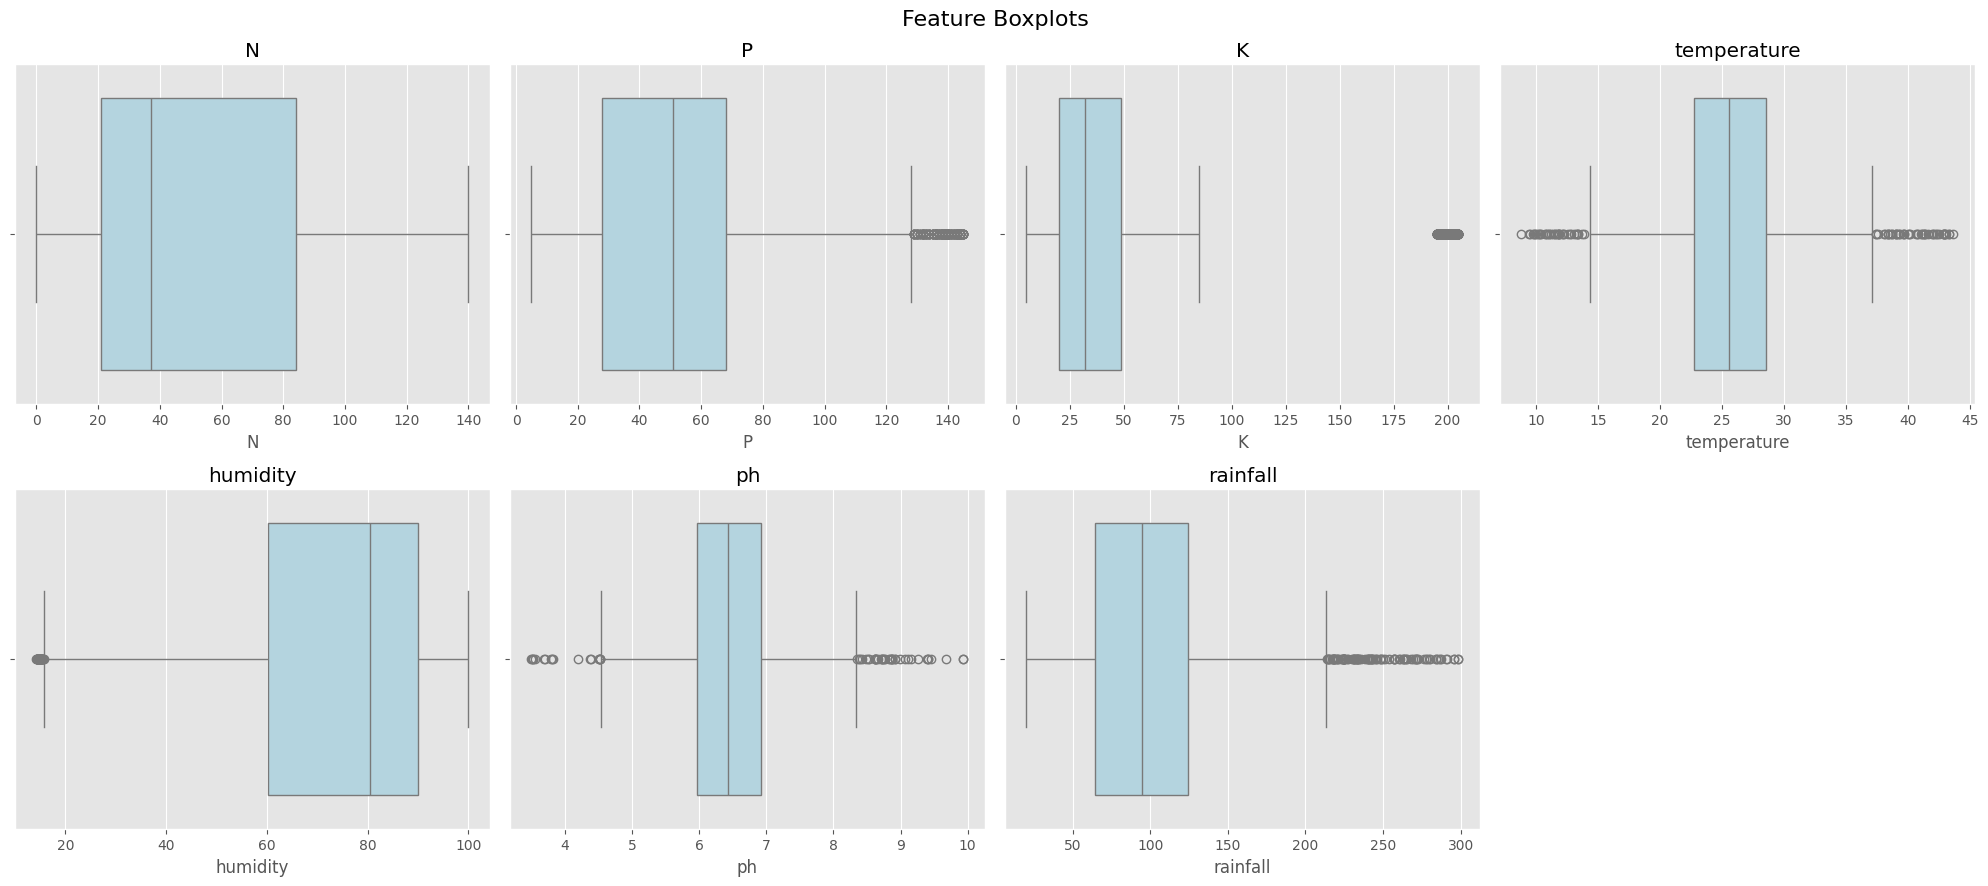

In [ ]:

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
fig.suptitle("Feature Boxplots", fontsize=16)
for ax, c in zip(axes.ravel(), FEATURES):
    sns.boxplot(x=df[c], ax=ax, color="lightblue"); ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig('fig3_feature_boxplot.png')
plt.show()



## **Figure 4 Correlation matrix**
**Key observation:**
phosphorus ↔ potassium = 0.74 indicatting that there is a strong linear correlation between the 2 FEATURES → samples with high phsphorus also have high potassium values.

The remaining correlations are relativly weak. Low correlation between two FEATURES does not mean either feature is unimportant for predicting a crop.

**Descision:** keep all FEATURES for initial models and investigate feature importance later after training.


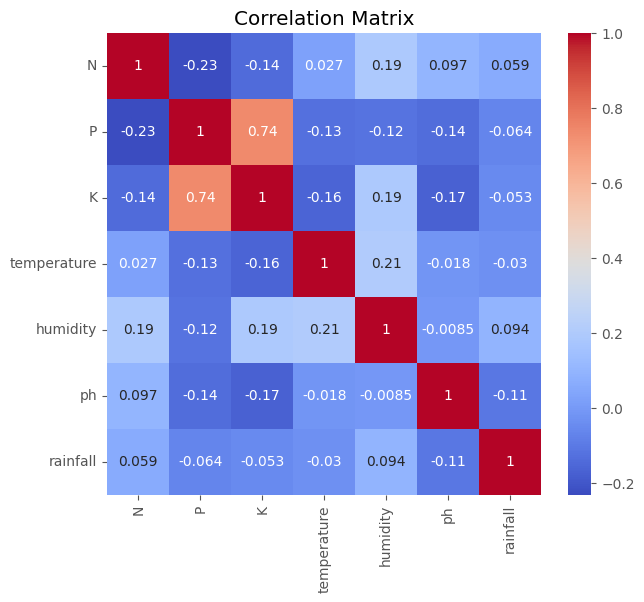

In [ ]:
#show correlation between FEATURES
corr = df[FEATURES].corr()
plt.figure(figsize = (7, 6))
sns.heatmap(corr, annot = True, cmap = "coolwarm")
plt.title("Correlation Matrix")
plt.savefig('fig4_correlation_matrix.png')
plt.show()


## **Figure 5 Growing Conditions across crops**

This heatmap compares growing conditions or FEATURES in the dataset with the corresponding crop. It helps show that crop classes have different feature combinations that our model will learn to distinguish the crops.

Key observations visible in the heatmap:


*   Rice: relatively high rainfall compared with other crops
*   Apple: high phosphorus and potassium values.
*   Grapes: high phosphorus and potassium values.
*   Cotton: relatively high nitrogen values.





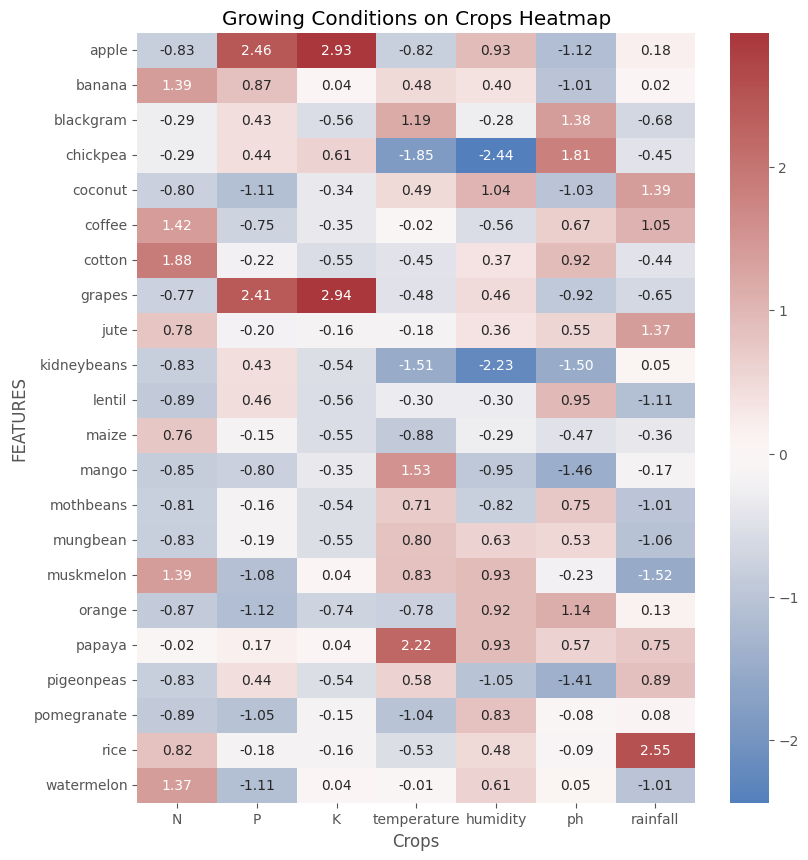

In [ ]:
#crop profile heatmap  - how does the FEATURES differ between the different crop types
crop_mean = df.groupby(TARGET)[FEATURES].mean()
z = (crop_mean - crop_mean.mean()) / crop_mean.std() #standarize averages of FEATURES
plt.figure(figsize = (9, 10))
sns.heatmap(z, cmap = "vlag", center=0, annot = True, fmt=".2f")
plt.title("Growing Conditions on Crops Heatmap")
plt.xlabel("Crops")
plt.ylabel("FEATURES")
plt.savefig('fig5_crop_conditions_heatmap.png')
plt.show()

## **Memory Optimization**

In [ ]:
def optimize_dtypes(df):
  "use smaller numeric types and categorical labels"
  opt = df.copy()
  for c in ["N","P","K"]:
    opt[c] = opt[c].astype("int16")
  for c in ["temperature","humidity","ph","rainfall"]:
    opt[c] = opt[c].astype("float32")
  opt["label"] = opt["label"].astype("category")
  return opt

before_MO = df.memory_usage(deep=True).sum() / (1024 **2)
df = optimize_dtypes(df)
after_MO = df.memory_usage(deep=True).sum() / (1024 **2)

print(f"Memory usage before optimization: {before_MO:.2f} MB")
print(f"Memory usage after optimization: {after_MO:.2f} MB")
print(f"Memory usage reduction: {100 * (before_MO - after_MO) / before_MO:.2f}%")

Memory usage before optimization: 0.24 MB
Memory usage after optimization: 0.05 MB
Memory usage reduction: 78.72%


In [ ]:
cleanDB = df.copy()
newcols = cleanDB.columns.tolist()
newcols[0] = "nitrogen"
newcols[1] = "phosphorus"
newcols[2] = "potassium"
cleanDB.columns = newcols
cleanDB.to_parquet("clean_crop.parquet", index=False)

# **Conclusion**
After visualizing and understanding the dataset , we were able to make aclean dataset with consistent column names that are understandable and better for reporting.

The clean dataset was saved into parquet format to save the optimized form of the dataset